# Drive Mount

In [1]:
from google.colab import drive
drive.mount('/content/grive')

Drive already mounted at /content/grive; to attempt to forcibly remount, call drive.mount("/content/grive", force_remount=True).


# **Training Process**

In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input, GlobalAveragePooling2D, Concatenate
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os
from sklearn import metrics
import joblib


## Load Training Images

In [3]:

# -------------------- Load & Preprocess Retinal Images --------------------


train_data_dir = '/content/grive/MyDrive/CVD Classification/Train'

train_data_gen = ImageDataGenerator()  # Rescale pixel values to [0, 1]

batch_size = 32

# Generate batches of training data

train_generator = train_data_gen.flow_from_directory(
    train_data_dir,
    target_size=(224, 224),  # Target size of the images
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False  # Shuffle the data
)

# Extract images and labels from the generator

X_train, Y_train = [], []

for _ in range(len(train_generator)):
    images, labels =  next(train_generator)
    X_train.append(images)
    Y_train.append(labels)

# Concatenate the batches to form the final training data
X_train = np.concatenate(X_train)
Y_train = np.concatenate(Y_train)

# Print the shape of the training data
print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)

Found 358 images belonging to 2 classes.
X_train shape: (358, 224, 224, 3)
Y_train shape: (358,)


# Load Training Clinical Data

In [4]:

# -------------------- Load & Preprocess Patient Data --------------------

# Load datasets
clinical_data1 = pd.read_csv('/content/grive/MyDrive/CVD Classification/clinical_data_cvd_train.csv')
clinical_data2 = pd.read_csv('/content/grive/MyDrive/CVD Classification/clinical_data_normal_train.csv')

# Concatenate both datasets
clinical_data = pd.concat([clinical_data1, clinical_data2], ignore_index=True)

# Handle missing values
clinical_data.fillna(clinical_data.mean(), inplace=True)

# Separate features and target labels
clinical_features = clinical_data.drop(['id', 'age', 'smoke', 'alco', 'active', 'cardio'], axis=1)  # Drop non-feature columns

# Normalize numerical features
scaler = StandardScaler()
clinical_features = scaler.fit_transform(clinical_features)

# Save the dictionary of encoders for later use in testing
joblib.dump(scaler, '/content/grive/MyDrive/CVD Classification/Scaling.pkl')

# Extract target labels
labels = clinical_data['cardio']


## Hybrid Deep Learning Model Building

In [5]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

tf.random.set_seed(42)

# -------------------- Define AlexNet --------------------
def build_alexnet(input_shape=(224, 224, 3)):
    model = Sequential([
        Conv2D(96, (11, 11), strides=4, activation='relu', input_shape=input_shape),
        MaxPooling2D((3, 3), strides=2),

        Conv2D(256, (5, 5), padding='same', activation='relu'),
        MaxPooling2D((3, 3), strides=2),

        Conv2D(384, (3, 3), padding='same', activation='relu'),
        Conv2D(384, (3, 3), padding='same', activation='relu'),
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        MaxPooling2D((3, 3), strides=2),

        Flatten(),
        Dense(1024, activation='relu'),
        Dropout(0.5),
        Dense(512, activation='relu')
    ])
    return model

# -------------------- Feature Extraction --------------------

# Load pre-trained VGG16 model
vgg_model = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
vgg_output = Flatten()(vgg_model.output)  # Pooling layer
vgg_output = Dense(512, activation='relu')(vgg_output)  # Feature extraction
vgg_model = Model(inputs=vgg_model.input, outputs=vgg_output)
vgg_model.save('/content/grive/MyDrive/CVD Classification/vgg_model.h5')

# Define and initialize AlexNet
alexnet_model = build_alexnet(input_shape=(224, 224, 3))

# Build the AlexNet model by calling it with a dummy input
dummy_input = tf.keras.Input(shape=(224, 224, 3))
alexnet_model(dummy_input)  # This line builds the model

alex_output = Flatten()(alexnet_model.output)  # Pooling layer
alexnet_model = Model(inputs=alexnet_model.input, outputs=alex_output)
alexnet_model.save('/content/grive/MyDrive/CVD Classification/alexnet_model.h5')

# -------------------- Extract Features --------------------
vgg_features = vgg_model.predict(X_train)  # Extract deep features from VGG16
alex_features = alexnet_model.predict(X_train)  # Extract deep features from AlexNet

# -------------------- Feature Fusion --------------------
image_features = np.concatenate((vgg_features, alex_features), axis=1)  # Concatenate image-based features

# Ensure clinical features are properly reshaped before concatenation
clinical_features = np.array(clinical_features)
if len(clinical_features.shape) == 1:
    clinical_features = clinical_features.reshape(-1, 1)  # Ensure correct shape

# Concatenate Image & Clinical Features
fused_features = np.concatenate((image_features, clinical_features), axis=1)

# -------------------- Define Hybrid Model --------------------
input_dim = fused_features.shape[1]  # Get feature vector length

hybrid_model = Sequential([
    Dense(512, activation='relu', input_shape=(input_dim,)),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dense(1, activation='sigmoid')  # Binary Classification (CVD or No-CVD)
])

# Compile Model
hybrid_model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

# Model Summary
hybrid_model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 16s 489ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 512)            │       528,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 725,761 (2.77 MB)

 Trainable params: 725,761 (2.77 MB)

 Non-trainable params: 0 (0.00 B)

## Train the Hybrid Model

In [6]:
# -------------------- Training --------------------
print("[INFO] Training the Hybrid Model...")

# Define training parameters
batch_size = 32  # Adjust for better performance
epochs = 100  # Can be tuned based on convergence


# Train the model
history = hybrid_model.fit(
    fused_features, Y_train,
    epochs=epochs,
    batch_size=batch_size
)

print("Training Completed!")

[INFO] Training the Hybrid Model...
Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 164ms/step - accuracy: 0.4951 - loss: 1.8102
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6122 - loss: 1.1873 
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6135 - loss: 1.0551 
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6136 - loss: 0.9209
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6369 - loss: 0.9910 
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6672 - loss: 0.9116 
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6749 - loss: 0.7152
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6631 - loss: 0.8232 
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6881 - loss: 0.7516 
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7551 - loss: 0.7004 
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6769 - loss: 0.7316 
Epoch 12/100
12/1

In [7]:
hybrid_model.save('/content/grive/MyDrive/CVD Classification/Model1.h5')

## Training Accuracy and Loss

dict_keys(['accuracy', 'loss'])


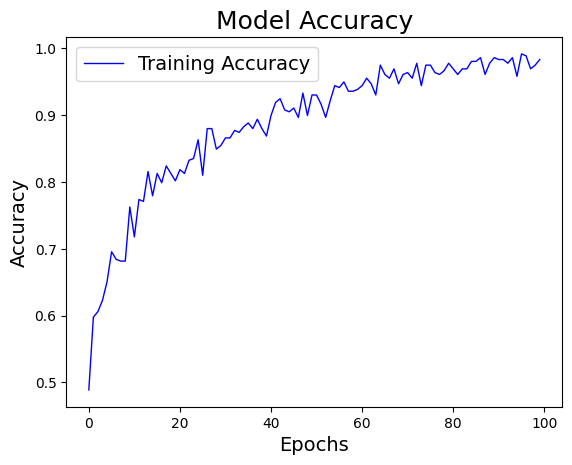

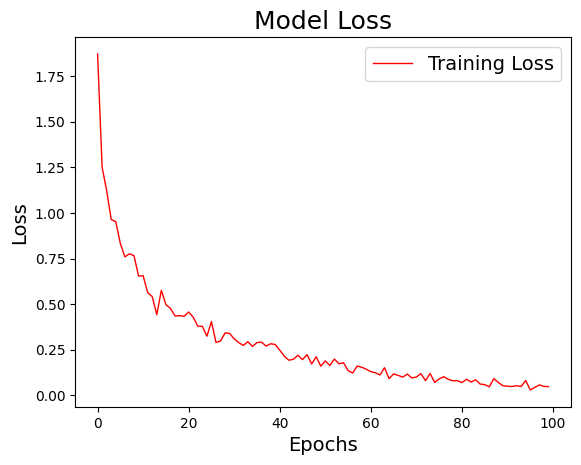

In [8]:
# summarize history for accuracy and loss

print(history.history.keys())

history_dict = history.history
acc = history_dict['accuracy']
loss = history_dict['loss']


# Accuracy Curves

plt.plot(acc,'-b',linewidth=1.0)
plt.title('Model Accuracy',fontsize=18)
plt.xlabel('Epochs',fontsize=14)
plt.ylabel('Accuracy',fontsize=14)
plt.legend(['Training Accuracy'], fontsize=14)
plt.grid(False)
plt.show()

# Loss Curves

plt.plot(loss,'-r',linewidth=1.0)
plt.title('Model Loss',fontsize=18)
plt.xlabel('Epochs',fontsize=14)
plt.ylabel('Loss',fontsize=14)
plt.legend(['Training Loss'], fontsize=14)
plt.grid(False)
plt.show()


# **Testing Process**

In [9]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model
from sklearn.preprocessing import StandardScaler
import pandas as pd

# -------------------- Load Test Images --------------------
test_dir = '/content/grive/MyDrive/CVD Classification/Test'

test_data_gen = ImageDataGenerator().flow_from_directory(
    directory=test_dir, target_size=(224,224), shuffle=False, class_mode='binary'
)

# Extract images & labels
X_test, Y_test = [], []
for _ in range(len(test_data_gen)):
    images, labels = next(test_data_gen)
    X_test.append(images)
    Y_test.append(labels)

X_test = np.concatenate(X_test)
Y_test = np.concatenate(Y_test)

# Get image file names
image_file_names = test_data_gen.filenames

# -------------------- Load & Process Clinical Data --------------------
clinical_data3 = pd.read_csv('/content/grive/MyDrive/CVD Classification/clinical_data_cvd_test.csv')
clinical_data4 = pd.read_csv('/content/grive/MyDrive/CVD Classification/clinical_data_normal_test.csv')

clinical_data = pd.concat([clinical_data3, clinical_data4])

# Handle missing values
clinical_data.fillna(clinical_data.mean(), inplace=True)

# Extract relevant features
clinical_features = clinical_data.drop(['id', 'age', 'smoke', 'alco', 'active', 'cardio'], axis=1)

# Normalize clinical features
clinical_features = scaler.transform(clinical_features)

# -------------------- Feature Extraction --------------------
# -------------------- Load Pretrained Feature Extractors --------------------
vgg_model = tf.keras.models.load_model('/content/grive/MyDrive/CVD Classification/vgg_model.h5')
alexnet_model = tf.keras.models.load_model('/content/grive/MyDrive/CVD Classification/alexnet_model.h5')

#
vgg_features = vgg_model.predict(X_test)
alex_features = alexnet_model.predict(X_test)

# Concatenate Image Features
image_features = np.concatenate((vgg_features, alex_features), axis=1)

# Fuse with Clinical Data
test_fused_features = np.concatenate((image_features, clinical_features), axis=1)

# -------------------- Load Model & Predict --------------------
model = load_model('/content/grive/MyDrive/CVD Classification/Model1.h5')

if model:
    print("[INFO] Model loaded successfully!")

Y_pred = model.predict(test_fused_features)

# Convert probability to binary labels
test_preds = (Y_pred > 0.5).astype(int).flatten()

# Create a DataFrame to store image file names & predictions
results_df = pd.DataFrame({'File Name': image_file_names, 'Classification Result': test_preds})

# Display Results
print(results_df)

Found 256 images belonging to 2 classes.


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 154ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


[INFO] Model loaded successfully!
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step  
          File Name  Classification Result
0       CVD/102.png                      0
1       CVD/103.png                      0
2       CVD/110.png                      0
3       CVD/111.png                      0
4       CVD/112.png                      0
..              ...                    ...
251  Normal/623.png                      1
252  Normal/626.png                      1
253  Normal/627.png                      1
254  Normal/628.png                      1
255  Normal/629.png                      1

[256 rows x 2 columns]


In [10]:
# Save results
results_df.to_csv('test_results.csv', index=False)

# **Performance Measure**

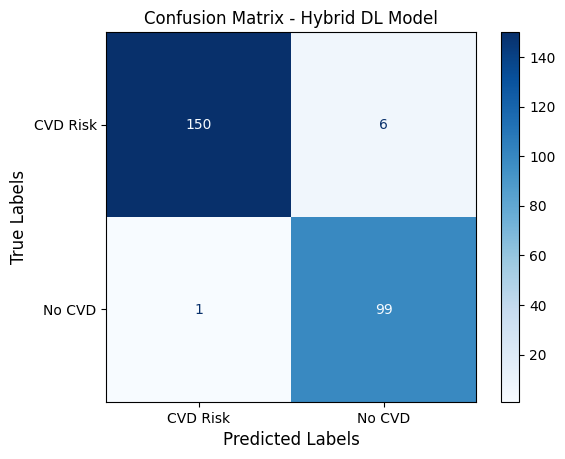

In [11]:
# Compute confusion matrix
confusion_matrix = metrics.confusion_matrix(Y_test, test_preds)

# Display confusion matrix
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix, display_labels=['CVD Risk','No CVD'])

# Plot confusion matrix
cm_display.plot(cmap="Blues", values_format="d")  # 'd' for integer values
plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.title('Confusion Matrix - Hybrid DL Model')
plt.xticks(rotation=0)
plt.grid(False)
plt.show()

In [12]:
from sklearn.metrics import accuracy_score, classification_report

# Compute accuracy
score = round(accuracy_score(Y_test, test_preds), 4) * 100
print("Accuracy of the Hybrid DL Model: {}%".format(score))
print()

# Compute Precision, Recall, and F1-Score
print("Classification Report:")
print(classification_report(Y_test, test_preds, digits=4))

Accuracy of the Hybrid DL Model: 97.27%

Classification Report:
              precision    recall  f1-score   support

         0.0     0.9934    0.9615    0.9772       156
         1.0     0.9429    0.9900    0.9659       100

    accuracy                         0.9727       256
   macro avg     0.9681    0.9758    0.9715       256
weighted avg     0.9736    0.9727    0.9728       256



8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


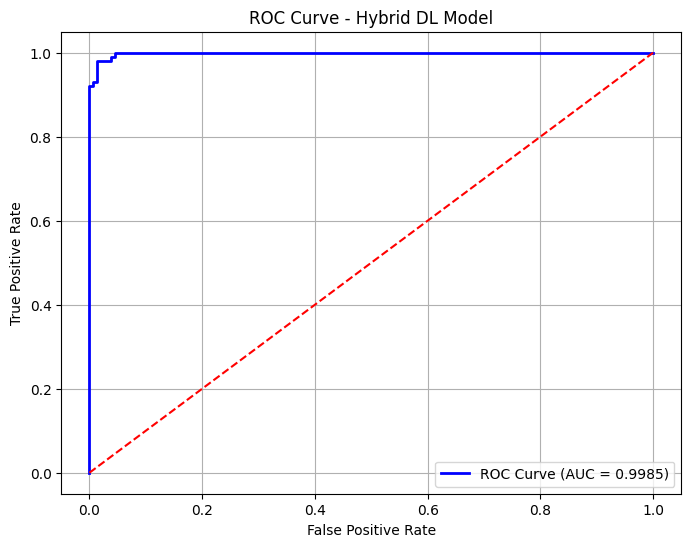

In [13]:
from sklearn.metrics import roc_curve, auc

# Compute ROC curve
fpr, tpr, _ = roc_curve(Y_test, model.predict(test_fused_features).ravel())

# Compute AUC
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label="ROC Curve (AUC = {:.4f})".format(roc_auc))
plt.plot([0, 1], [0, 1], color="red", linestyle="--")  # Diagonal line for reference
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Hybrid DL Model")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()